# Modern Architectures Demo

**Purpose**: This notebook builds the pieces of Chapter 6 and checks each against an independent reference: the parameter count of ten real models from their configuration files, a grouped-query attention layer, a KV cache, a simplified latent cache, rotary-frequency scaling, a mixture-of-experts router, and a seeded comparison of post-norm and pre-norm training. Every section ends in assertions, so a silent change to any formula fails the notebook.

**Data**: model configurations are read from the Hugging Face hub at pinned commits when a network is available, and from copies committed in `data/` otherwise; set `LLMATLAS_OFFLINE=1` to skip the network. Both sources are verified against the committed checksums, so the results do not depend on which one is used. The training text is Jane Austen's *Pride and Prejudice*, public domain, from Project Gutenberg.

## 1. Setup

In [1]:
import hashlib
import json
import math
import os
import time
import urllib.error
import urllib.request
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams["figure.dpi"] = 100

DATA = Path("data")
OFFLINE = os.environ.get("LLMATLAS_OFFLINE") == "1"


@contextmanager
def timed(label):
    start = time.perf_counter()
    yield
    print(f"[{label}: {time.perf_counter() - start:.1f} s]")


def sha256(raw):
    return hashlib.sha256(raw).hexdigest()

(nb-arch-configs)=
## 2. Real Configurations and Exact Parameter Counts

Seven ungated models are read from their pinned commits (`data/pins.json`). Each file is checked against `data/checksums.json`, whether it came from the hub or from the committed copy. Three gated models (Llama 3.1 8B and 70B, Gemma 2 9B) cannot be downloaded without an account; their architectures are transcribed from their papers and checked against the exact parameter totals the hub publishes for them.

In [2]:
PINS = json.loads((DATA / "pins.json").read_text())
CHECKSUMS = json.loads((DATA / "checksums.json").read_text())["sha256"]
live_ok = not OFFLINE


def load_config(repo):
    """The model's config.json: from the hub at the pinned commit if reachable, else committed."""
    global live_ok
    name = f"configs/{repo.replace('/', '__')}.json"
    committed = (DATA / name).read_bytes()
    assert sha256(committed) == CHECKSUMS[name], f"committed {name} does not match its checksum"
    if live_ok:
        url = f"https://huggingface.co/{repo}/resolve/{PINS[repo]}/config.json"
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "llmatlas-notebook/0.1"})
            with urllib.request.urlopen(request, timeout=10) as response:
                live = response.read()
            if sha256(live) == CHECKSUMS[name]:
                return json.loads(live), "hub, pinned commit"
            return json.loads(committed), "committed copy (hub bytes differ)"
        except (urllib.error.URLError, TimeoutError, OSError) as error:  # incl. HTTP 401/403/404/429
            live_ok = False  # do not wait for a timeout on every remaining model
            print(f"hub unreachable ({type(error).__name__}); using committed copies")
    return json.loads(committed), "committed copy"


with timed("configs"):
    CONFIGS, SOURCES = {}, {}
    for repo in PINS:
        CONFIGS[repo], SOURCES[repo] = load_config(repo)
for repo, source in SOURCES.items():
    print(f"{repo:32} {CONFIGS[repo]['model_type']:12} {source}")

[configs: 1.3 s]
Qwen/Qwen2.5-7B                  qwen2        hub, pinned commit
allenai/OLMo-2-1124-7B           olmo2        hub, pinned commit
allenai/OLMoE-1B-7B-0924         olmoe        hub, pinned commit
deepseek-ai/DeepSeek-V2-Lite     deepseek_v2  hub, pinned commit
deepseek-ai/DeepSeek-V3          deepseek_v3  hub, pinned commit
mistralai/Mistral-7B-v0.1        mistral      hub, pinned commit
mistralai/Mixtral-8x7B-v0.1      mixtral      hub, pinned commit


The three gated models, transcribed from their papers. Gemma 2's head dimension (256) is larger than $d_{model}/n_{heads}$, and its embeddings are tied.

In [3]:
PAPER_CONFIGS = {
    "meta-llama/Llama-3.1-8B": {
        "model_type": "llama", "hidden_size": 4096, "num_hidden_layers": 32,
        "num_attention_heads": 32, "num_key_value_heads": 8, "intermediate_size": 14336,
        "vocab_size": 128256, "tie_word_embeddings": False},
    "meta-llama/Llama-3.1-70B": {
        "model_type": "llama", "hidden_size": 8192, "num_hidden_layers": 80,
        "num_attention_heads": 64, "num_key_value_heads": 8, "intermediate_size": 28672,
        "vocab_size": 128256, "tie_word_embeddings": False},
    "google/gemma-2-9b": {
        "model_type": "gemma2", "hidden_size": 3584, "num_hidden_layers": 42,
        "num_attention_heads": 16, "num_key_value_heads": 8, "head_dim": 256,
        "intermediate_size": 14336, "vocab_size": 256000, "tie_word_embeddings": True},
}
ALL_CONFIGS = {**CONFIGS, **PAPER_CONFIGS}

The parameter counter and the KV-cache function are the ones printed in the chapter, copied from its text.

In [4]:
SUPPORTED = ("llama", "qwen2", "mistral", "mixtral", "olmo2", "olmoe", "gemma2",
             "deepseek_v2", "deepseek_v3")


def count_params(cfg):
    """Parameter counts from a Hugging Face config.json dictionary.

    Returns exact integers: total (what the checkpoint stores, excluding DeepSeek's multi-token
    prediction layer), and the parameters one token touches, with and without the input
    embedding (vendors differ on which they call "active").
    """
    kind = cfg["model_type"]
    if kind not in SUPPORTED:
        raise ValueError(f"unsupported model_type {kind!r}; supported: {SUPPORTED}")
    H, L, V = cfg["hidden_size"], cfg["num_hidden_layers"], cfg["vocab_size"]
    nh = cfg["num_attention_heads"]
    nkv = cfg.get("num_key_value_heads") or nh
    dh = cfg.get("head_dim") or H // nh

    # Attention, per layer
    if kind.startswith("deepseek"):  # multi-head latent attention
        dn, dr, dv = cfg["qk_nope_head_dim"], cfg["qk_rope_head_dim"], cfg["v_head_dim"]
        kv_rank, q_rank = cfg["kv_lora_rank"], cfg["q_lora_rank"]
        q = H * nh * (dn + dr) if q_rank is None else H * q_rank + q_rank + q_rank * nh * (dn + dr)
        kv = H * (kv_rank + dr) + kv_rank + kv_rank * nh * (dn + dv)
        attn = q + kv + nh * dv * H
    else:
        attn = H * nh * dh + 2 * H * nkv * dh + nh * dh * H
        if kind == "qwen2":
            attn += nh * dh + 2 * nkv * dh  # biases on q, k and v (set in the model code)
        if kind in ("olmo2", "olmoe"):
            attn += nh * dh + nkv * dh  # QK-norm weights over the full q and k projections
    # RMSNorm weights per layer: two (before or after each sublayer), or four for Gemma 2,
    # which normalises both before and after each sublayer
    norms = (4 if kind == "gemma2" else 2) * H

    def gated(width):  # SwiGLU feed-forward: gate, up and down projections
        return 3 * H * width

    def ffn(layer):  # (total, active) feed-forward parameters of one layer
        if kind in ("llama", "qwen2", "mistral", "olmo2", "gemma2"):
            return gated(cfg["intermediate_size"]), gated(cfg["intermediate_size"])
        if kind in ("mixtral", "olmoe"):
            experts = cfg.get("num_local_experts") or cfg["num_experts"]
            top_k, width = cfg["num_experts_per_tok"], cfg["intermediate_size"]
            return H * experts + experts * gated(width), H * experts + top_k * gated(width)
        if layer < cfg["first_k_dense_replace"]:  # DeepSeek: dense layers come first
            return gated(cfg["intermediate_size"]), gated(cfg["intermediate_size"])
        assert cfg.get("moe_layer_freq", 1) == 1
        experts, top_k = cfg["n_routed_experts"], cfg["num_experts_per_tok"]
        width, shared = cfg["moe_intermediate_size"], cfg["n_shared_experts"]
        router = H * experts + (experts if kind == "deepseek_v3" else 0)  # V3: per-expert bias
        return (router + shared * gated(width) + experts * gated(width),
                router + shared * gated(width) + top_k * gated(width))

    tied = bool(cfg.get("tie_word_embeddings"))
    body = L * (attn + norms)
    ffn_total = sum(ffn(i)[0] for i in range(L))
    ffn_active = sum(ffn(i)[1] for i in range(L))
    total = V * H + (0 if tied else V * H) + H + body + ffn_total
    active_without_embedding = V * H + H + body + ffn_active  # output head, no input embedding
    active_with_embedding = active_without_embedding + (0 if tied else V * H)
    return {"total": total, "active_with_embedding": active_with_embedding,
            "active_without_embedding": active_without_embedding}

In [5]:
def kv_cache_elements_per_token(cfg):
    """KV-cache elements one token occupies across all layers of a decoder model."""
    layers = cfg["num_hidden_layers"]
    if cfg["model_type"].startswith("deepseek"):  # MLA caches one latent and one rope key
        return layers * (cfg["kv_lora_rank"] + cfg["qk_rope_head_dim"])
    n_heads = cfg["num_attention_heads"]
    n_kv = cfg.get("num_key_value_heads") or n_heads
    head_dim = cfg.get("head_dim") or cfg["hidden_size"] // n_heads
    return layers * 2 * n_kv * head_dim

Three checks, each catching a different kind of mistake. First, against the checkpoint: the element counts were read from the tensor shapes in each safetensors header (`tools/fetch_arch_samples.py`), which does not depend on whether a model is stored in float32, BF16 or FP8. Second, against the hub's published total for the gated models. Third, against each vendor's own published figure, in that vendor's convention for "active" parameters; the other convention must miss.

In [6]:
CHECKPOINT = json.loads((DATA / "checkpoint_counts.json").read_text())
HUB_TOTALS = json.loads((DATA / "hub_totals.json").read_text())
COUNTS = {repo: count_params(cfg) for repo, cfg in ALL_CONFIGS.items()}

# 1. Exact agreement with the element counts of the stored tensors
for repo in PINS:
    counted = CHECKPOINT[repo]["elements_counted"]
    assert COUNTS[repo]["total"] == counted, (repo, COUNTS[repo]["total"], counted)
print("checkpoint element counts reproduced exactly for", len(PINS), "models")
v3 = CHECKPOINT["deepseek-ai/DeepSeek-V3"]
print(f"  DeepSeek-V3 also stores {v3['elements_mtp_layer']:,} multi-token-prediction and "
      f"{v3['elements_fp8_scales']:,} FP8-scale elements, counted separately")

# 2. Gated models: the hub's public metadata reports the exact total
for repo in PAPER_CONFIGS:
    assert COUNTS[repo]["total"] == HUB_TOTALS[repo]["elements_total"], repo
print("hub totals reproduced exactly for", ", ".join(PAPER_CONFIGS))

# 3. Published figures (billions): (total, tolerance, active, convention, tolerance)
# Tolerances are half a unit in the last published digit, widened where the vendor truncates
# (Qwen 7.6156 -> 7.61, DeepSeek-V2-Lite 2.451 -> 2.4) or rounds up (Mistral 7.2417 -> 7.3).
PUBLISHED = {
    "Qwen/Qwen2.5-7B": (7.61, 0.01, None, None, None),
    "allenai/OLMo-2-1124-7B": (7.3, 0.05, None, None, None),
    "allenai/OLMoE-1B-7B-0924": (6.9, 0.05, 1.3, "with", 0.05),
    "deepseek-ai/DeepSeek-V2-Lite": (15.7, 0.05, 2.4, "without", 0.1),
    "deepseek-ai/DeepSeek-V3": (671, 0.5, 37, "without", 0.5),
    "mistralai/Mistral-7B-v0.1": (7.3, 0.1, None, None, None),
    "mistralai/Mixtral-8x7B-v0.1": (46.7, 0.05, 12.9, "with", 0.05),
}
for repo, (total, tol, active, convention, tol_active) in PUBLISHED.items():
    got = COUNTS[repo]
    assert abs(got["total"] / 1e9 - total) <= tol, (repo, got["total"] / 1e9, total)
    if active is not None:
        other = "without" if convention == "with" else "with"
        right = got[f"active_{convention}_embedding"] / 1e9
        wrong = got[f"active_{other}_embedding"] / 1e9
        assert abs(right - active) <= tol_active, (repo, convention, right, active)
        assert abs(wrong - active) > tol_active, (repo, other, wrong, active)  # other convention misses
        print(f"{repo:32} active {right:7.3f}B ({convention} embedding) vs published {active}B; "
              f"{other}: {wrong:.3f}B misses")

# Coverage: the set contains a dense, a sparse and a latent-attention model
kinds = {cfg["model_type"] for cfg in CONFIGS.values()}
assert {"qwen2", "mixtral", "deepseek_v3"} <= kinds

checkpoint element counts reproduced exactly for 7 models
  DeepSeek-V3 also stores 13,463,426,304 multi-token-prediction and 41,540,496 FP8-scale elements, counted separately
hub totals reproduced exactly for meta-llama/Llama-3.1-8B, meta-llama/Llama-3.1-70B, google/gemma-2-9b
allenai/OLMoE-1B-7B-0924         active   1.282B (with embedding) vs published 1.3B; without: 1.179B misses
deepseek-ai/DeepSeek-V2-Lite     active   2.451B (without embedding) vs published 2.4B; with: 2.661B misses
deepseek-ai/DeepSeek-V3          active  36.626B (without embedding) vs published 37B; with: 37.552B misses
mistralai/Mixtral-8x7B-v0.1      active  12.880B (with embedding) vs published 12.9B; without: 12.749B misses


The derived columns used in the chapter: embedding share, feed-forward share (dense models), and the bf16 KV-cache bytes per token for every layer.

model                                params  embed %  ffn %  KV B/token
Qwen/Qwen2.5-7B                       7.62B     14.3   74.9      57,344
allenai/OLMo-2-1124-7B                7.30B     11.3   59.3     524,288
allenai/OLMoE-1B-7B-0924              6.92B      3.0      -     131,072
deepseek-ai/DeepSeek-V2-Lite         15.71B      2.7      -      31,104
deepseek-ai/DeepSeek-V3             671.03B      0.3      -      70,272
mistralai/Mistral-7B-v0.1             7.24B      3.6   77.8     131,072
mistralai/Mixtral-8x7B-v0.1          46.70B      0.6      -     131,072
meta-llama/Llama-3.1-8B               8.03B     13.1   70.2     131,072
meta-llama/Llama-3.1-70B             70.55B      3.0   79.9     327,680
google/gemma-2-9b                     9.24B      9.9   70.1     344,064


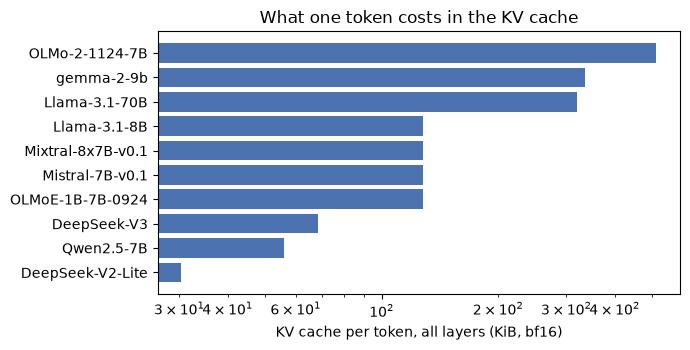

In [7]:
rows = []
for repo, cfg in ALL_CONFIGS.items():
    n, hidden, layers, vocab = COUNTS[repo]["total"], cfg["hidden_size"], cfg["num_hidden_layers"], cfg["vocab_size"]
    tied = bool(cfg.get("tie_word_embeddings"))
    embedding_share = vocab * hidden * (1 if tied else 2) / n
    dense = "intermediate_size" in cfg and not any(k in cfg for k in ("num_experts", "num_local_experts", "n_routed_experts"))
    ffn_share = 3 * hidden * cfg["intermediate_size"] * layers / n if dense else None
    kv_bytes = 2 * kv_cache_elements_per_token(cfg)
    rows.append((repo, n, embedding_share, ffn_share, kv_bytes))

print(f"{'model':32} {'params':>10} {'embed %':>8} {'ffn %':>6} {'KV B/token':>11}")
for repo, n, emb, ffn, kv in rows:
    ffn_text = f"{100 * ffn:6.1f}" if ffn is not None else "     -"
    print(f"{repo:32} {n / 1e9:9.2f}B {100 * emb:8.1f} {ffn_text} {kv:11,}")

shares = [ffn for *_, ffn, _ in rows if ffn is not None]
assert 0.59 < min(shares) < 0.60 and 0.79 < max(shares) < 0.81  # OLMo 2 7B ... Llama 3.1 70B
kv_bytes = {repo: kv for repo, *_, kv in rows}
assert kv_bytes["meta-llama/Llama-3.1-8B"] == 131072 and kv_bytes["deepseek-ai/DeepSeek-V3"] == 70272
assert kv_bytes["deepseek-ai/DeepSeek-V3"] == 61 * (512 + 64) * 2  # MLA: latent + rotary key per layer

order = sorted(kv_bytes, key=kv_bytes.get)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([name.split("/")[1] for name in order], [kv_bytes[name] / 1024 for name in order], color="#4c72b0")
ax.set_xscale("log")
ax.set_xlabel("KV cache per token, all layers (KiB, bf16)")
ax.set_title("What one token costs in the KV cache")
plt.tight_layout()
plt.show()

(nb-arch-block)=
## 3. The Block: RMSNorm, Grouped-Query Attention, SwiGLU

`RMSNorm`, `SwiGLU`, `PreLNBlock` and `apply_rope` below are copied from Chapter 1. The new piece is the attention layer, which supports any number of key/value heads (`n_kv_heads = n_heads` is multi-head attention, `1` is multi-query) and exposes `project` and `attend` separately so the cache section can reuse them.

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class RMSNorm(nn.Module):
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d_model))

    def forward(self, x):
        rms = torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return self.weight * x / rms


class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden=None):
        super().__init__()
        hidden = hidden or int(8 * d_model / 3)
        self.w1 = nn.Linear(d_model, hidden, bias=False)
        self.w3 = nn.Linear(d_model, hidden, bias=False)
        self.w2 = nn.Linear(hidden, d_model, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class PreLNBlock(nn.Module):
    """A LLaMA-style block: pre-norm, RMSNorm, SwiGLU. Attention is any module with
    forward(x, x, x) -> output (RoPE and grouped-query attention live inside it)."""

    def __init__(self, d_model, attention):
        super().__init__()
        self.attention = attention
        self.norm1 = RMSNorm(d_model)
        self.norm2 = RMSNorm(d_model)
        self.ffn = SwiGLU(d_model)

    def forward(self, x):
        h = self.norm1(x)
        x = x + self.attention(h, h, h)
        return x + self.ffn(self.norm2(x))

In [9]:
def apply_rope(x, positions, base=10000.0):
    """Rotary position embedding (Su et al., 2021), applied to queries and keys.

    x: [..., seq, d]; positions: [seq]. Consecutive pairs of features are rotated by an
    angle m * theta_i, where m is the position and theta_i = base^(-2i/d). Because a rotation
    preserves norms and q_m . k_n then depends only on m - n, RoPE encodes relative position
    without any parameters.
    """
    d = x.size(-1)
    inv_freq = 1.0 / (base ** (torch.arange(0, d, 2).float() / d))   # [d/2]
    angles = positions.float()[:, None] * inv_freq[None, :]           # [seq, d/2]
    cos, sin = torch.cos(angles), torch.sin(angles)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * cos - x2 * sin
    out[..., 1::2] = x1 * sin + x2 * cos
    return out

In [10]:
class GQAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, rope_base=10000.0):
        super().__init__()
        assert n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv, self.d_head = n_heads, n_kv_heads, d_model // n_heads
        self.rope_base = rope_base
        self.wq = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.wk = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.wv = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.wo = nn.Linear(n_heads * self.d_head, d_model, bias=False)

    def project(self, x, positions):
        """Queries, keys (after RoPE) and values: [batch, heads, seq, d_head]."""
        b, t, _ = x.shape
        q = self.wq(x).view(b, t, self.n_heads, self.d_head).transpose(1, 2)
        k = self.wk(x).view(b, t, self.n_kv, self.d_head).transpose(1, 2)
        v = self.wv(x).view(b, t, self.n_kv, self.d_head).transpose(1, 2)
        return apply_rope(q, positions, self.rope_base), apply_rope(k, positions, self.rope_base), v

    def attend(self, q, k, v, causal=True):
        group = self.n_heads // self.n_kv
        k, v = k.repeat_interleave(group, dim=1), v.repeat_interleave(group, dim=1)
        return F.scaled_dot_product_attention(q, k, v, is_causal=causal)

    def forward(self, x, _keys=None, _values=None):  # the signature PreLNBlock calls
        b, t, _ = x.shape
        q, k, v = self.project(x, torch.arange(t))
        return self.wo(self.attend(q, k, v).transpose(1, 2).reshape(b, t, -1))


class PostLNBlock(nn.Module):
    """The 2017 arrangement with RMSNorm and SwiGLU: normalize after each residual addition."""

    def __init__(self, d_model, attention):
        super().__init__()
        self.attention = attention
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.ffn = SwiGLU(d_model)

    def forward(self, x):
        x = self.norm1(x + self.attention(x, x, x))
        return self.norm2(x + self.ffn(x))


class TinyLM(nn.Module):
    """A byte-level decoder with tied embeddings; `style` is "pre" or "post"."""

    def __init__(self, vocab=256, d_model=64, n_layers=4, n_heads=4, n_kv_heads=2, style="pre"):
        super().__init__()
        self.embed = nn.Embedding(vocab, d_model)
        nn.init.normal_(self.embed.weight, std=0.02)
        block = PreLNBlock if style == "pre" else PostLNBlock
        self.blocks = nn.ModuleList(
            [block(d_model, GQAttention(d_model, n_heads, n_kv_heads)) for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model) if style == "pre" else nn.Identity()

    def forward(self, tokens):
        x = self.embed(tokens)
        for block in self.blocks:
            x = block(x)
        return self.final_norm(x) @ self.embed.weight.T

Checks. RMSNorm against PyTorch's `nn.RMSNorm`; grouped-query attention (and multi-query, the one-group case) against a plain softmax implementation that uses multi-head attention with the key/value weights repeated per group; causality; and the module's parameter count against `count_params`.

In [11]:
torch.manual_seed(1)

# RMSNorm vs torch.nn.RMSNorm, float64, random weights
ours, ref = RMSNorm(64).double(), nn.RMSNorm(64, eps=1e-6).double()
with torch.no_grad():
    ours.weight.copy_(torch.randn(64)); ref.weight.copy_(ours.weight)
x = torch.randn(3, 5, 64, dtype=torch.float64)
assert torch.allclose(ours(x), ref(x), atol=1e-12)


def reference_attention(att, x):
    """Explicit softmax attention with one key/value head per query head (weights repeated)."""
    b, t, _ = x.shape
    h, g = att.n_heads, att.n_heads // att.n_kv
    def expand(weight):  # [n_kv * d_head, d_model] -> [n_heads * d_head, d_model]
        w = weight.view(att.n_kv, att.d_head, -1)
        return w.repeat_interleave(g, dim=0).reshape(h * att.d_head, -1)
    q = (x @ att.wq.weight.T).view(b, t, h, att.d_head).transpose(1, 2)
    k = (x @ expand(att.wk.weight).T).view(b, t, h, att.d_head).transpose(1, 2)
    v = (x @ expand(att.wv.weight).T).view(b, t, h, att.d_head).transpose(1, 2)
    pos = torch.arange(t)
    q, k = apply_rope(q, pos), apply_rope(k, pos)
    scores = q @ k.transpose(-1, -2) / math.sqrt(att.d_head)
    scores = scores.masked_fill(torch.triu(torch.ones(t, t, dtype=torch.bool), 1), float("-inf"))
    out = (scores.softmax(-1) @ v).transpose(1, 2).reshape(b, t, -1)
    return out @ att.wo.weight.T


x = torch.randn(2, 9, 64, dtype=torch.float64)
for n_kv in (4, 2, 1):  # multi-head, grouped-query (2 groups), multi-query
    att = GQAttention(64, 4, n_kv).double()
    assert torch.allclose(att(x), reference_attention(att, x), atol=1e-10), n_kv
print("RMSNorm and attention match their references for 4, 2 and 1 key/value heads")

# The chapter's grouped_query_attention function is the same computation as the module's attend

RMSNorm and attention match their references for 4, 2 and 1 key/value heads


In [12]:
import torch
import torch.nn.functional as F


def grouped_query_attention(q, k, v):
    """q: [batch, n_heads, seq, d_h]; k, v: [batch, n_kv, seq, d_h], n_heads % n_kv == 0."""
    group = q.size(1) // k.size(1)
    k = k.repeat_interleave(group, dim=1)  # each KV head serves `group` adjacent query heads
    v = v.repeat_interleave(group, dim=1)
    return F.scaled_dot_product_attention(q, k, v, is_causal=True)

In [13]:
att = GQAttention(64, 4, 2).double()
q, k, v = att.project(x, torch.arange(9))
assert torch.allclose(grouped_query_attention(q, k, v), att.attend(q, k, v), atol=1e-12)

# Causality: changing the last tokens does not change earlier outputs
model = TinyLM().double()
tokens = torch.randint(0, 256, (2, 16))
changed = tokens.clone()
changed[:, 10:] = torch.randint(0, 256, (2, 6))
with torch.no_grad():
    a, b = model(tokens), model(changed)
assert torch.allclose(a[:, :10], b[:, :10], atol=1e-12) and not torch.allclose(a[:, 10:], b[:, 10:])

# The module has exactly the parameters count_params predicts for its configuration
TINY = {"model_type": "llama", "hidden_size": 64, "num_hidden_layers": 4, "num_attention_heads": 4,
        "num_key_value_heads": 2, "intermediate_size": 170, "vocab_size": 256,
        "tie_word_embeddings": True}
measured = sum(p.numel() for p in TinyLM().parameters())
assert measured == count_params(TINY)["total"], (measured, count_params(TINY)["total"])
print(f"TinyLM has {measured:,} parameters, as count_params predicts")

TinyLM has 196,672 parameters, as count_params predicts


(nb-arch-kvcache)=
## 4. The KV Cache

Decoding one token at a time with a cache must give the same logits as running the whole sequence at once. The loop below is the cache in its simplest form: every layer appends the new token's keys and values, and the query attends to everything stored (no mask is needed, because the cache holds only the past).

In [14]:
@torch.no_grad()
def decode_with_cache(model, tokens):
    caches = [{"k": [], "v": []} for _ in model.blocks]
    logits = []
    for pos in range(tokens.shape[1]):
        x = model.embed(tokens[:, pos:pos + 1])
        for block, cache in zip(model.blocks, caches):
            att = block.attention
            q, k, v = att.project(block.norm1(x), torch.tensor([pos]))
            cache["k"].append(k)
            cache["v"].append(v)
            keys, values = torch.cat(cache["k"], dim=2), torch.cat(cache["v"], dim=2)
            out = att.attend(q, keys, values, causal=False).transpose(1, 2).reshape(x.shape[0], 1, -1)
            x = x + att.wo(out)
            x = x + block.ffn(block.norm2(x))
        logits.append(model.final_norm(x) @ model.embed.weight.T)
    return torch.cat(logits, dim=1), caches


tokens = torch.randint(0, 256, (2, 24))
for n_kv in (4, 2, 1):
    model = TinyLM(n_kv_heads=n_kv).double()
    with torch.no_grad():
        full = model(tokens)
    cached, caches = decode_with_cache(model, tokens)
    assert torch.allclose(full, cached, atol=1e-10), n_kv
    # Measured cache size per token equals the chapter's formula
    stored = sum(t.numel() for c in caches for t in c["k"] + c["v"]) / (tokens.shape[0] * tokens.shape[1])
    cfg = {**TINY, "num_key_value_heads": n_kv}
    assert stored == kv_cache_elements_per_token(cfg), (stored, kv_cache_elements_per_token(cfg))
    print(f"n_kv={n_kv}: cached decoding equals the full pass; cache {int(stored)} elements/token "
          f"(multi-head would be {kv_cache_elements_per_token({**TINY, 'num_key_value_heads': 4})})")

n_kv=4: cached decoding equals the full pass; cache 512 elements/token (multi-head would be 512)
n_kv=2: cached decoding equals the full pass; cache 256 elements/token (multi-head would be 512)


n_kv=1: cached decoding equals the full pass; cache 128 elements/token (multi-head would be 512)


A simplified multi-head latent attention layer. Only a small latent $c_t$ and a shared rotary key are cached. The reference expands the latent into full keys and values and runs ordinary attention; the decoding path never builds them, because the key up-projection is absorbed into the query and the value up-projection is applied after the weighted sum. This is a simplified layer (no query compression, one rotary key), not DeepSeek's implementation.

In [15]:
class MiniMLA(nn.Module):
    def __init__(self, d_model=64, n_heads=4, d_nope=16, d_rope=8, d_v=16, d_c=16, base=10000.0):
        super().__init__()
        self.h, self.dn, self.dr, self.dv, self.dc, self.base = n_heads, d_nope, d_rope, d_v, d_c, base
        self.wq = nn.Linear(d_model, n_heads * (d_nope + d_rope), bias=False)
        self.w_dkv = nn.Linear(d_model, d_c, bias=False)       # down-projection: what is cached
        self.w_kr = nn.Linear(d_model, d_rope, bias=False)     # rotary key, shared by all heads
        self.w_uk = nn.Linear(d_c, n_heads * d_nope, bias=False)
        self.w_uv = nn.Linear(d_c, n_heads * d_v, bias=False)
        self.wo = nn.Linear(n_heads * d_v, d_model, bias=False)

    def queries(self, x, positions):
        b, t, _ = x.shape
        q = self.wq(x).view(b, t, self.h, self.dn + self.dr).transpose(1, 2)
        return q[..., :self.dn], apply_rope(q[..., self.dn:], positions, self.base)

    def rotary_key(self, x, positions):
        return apply_rope(self.w_kr(x)[:, None], positions, self.base)[:, 0]  # [batch, seq, d_rope]

    def forward_expanded(self, x):
        """Reference: expand the latent to full keys and values, then ordinary causal attention."""
        b, t, _ = x.shape
        pos = torch.arange(t)
        q_nope, q_rope = self.queries(x, pos)
        c = self.w_dkv(x)
        k_nope = self.w_uk(c).view(b, t, self.h, self.dn).transpose(1, 2)
        v = self.w_uv(c).view(b, t, self.h, self.dv).transpose(1, 2)
        k_rope = self.rotary_key(x, pos)[:, None].expand(-1, self.h, -1, -1)
        out = F.scaled_dot_product_attention(
            torch.cat([q_nope, q_rope], -1), torch.cat([k_nope, k_rope], -1), v, is_causal=True)
        return self.wo(out.transpose(1, 2).reshape(b, t, -1))

    def decode_step(self, x_t, cache, position):
        """One token using only the cache of latents and rotary keys."""
        pos = torch.tensor([position])
        q_nope, q_rope = self.queries(x_t, pos)
        cache["c"].append(self.w_dkv(x_t))
        cache["kr"].append(self.rotary_key(x_t, pos))
        c, kr = torch.cat(cache["c"], 1), torch.cat(cache["kr"], 1)
        w_uk = self.w_uk.weight.view(self.h, self.dn, self.dc)
        w_uv = self.w_uv.weight.view(self.h, self.dv, self.dc)
        q_latent = torch.einsum("bhtn,hnc->bhtc", q_nope, w_uk)            # absorb W_UK into the query
        scores = torch.einsum("bhtc,bsc->bhts", q_latent, c) + torch.einsum("bhtr,bsr->bhts", q_rope, kr)
        weights = (scores / math.sqrt(self.dn + self.dr)).softmax(-1)
        latent = torch.einsum("bhts,bsc->bhtc", weights, c)                  # weighted sum of latents
        out = torch.einsum("bhtc,hvc->bhtv", latent, w_uv)                   # value up-projection after
        return self.wo(out.transpose(1, 2).reshape(x_t.shape[0], 1, -1))


mla = MiniMLA().double()
x = torch.randn(2, 12, 64, dtype=torch.float64)
with torch.no_grad():
    expanded = mla.forward_expanded(x)
    cache = {"c": [], "kr": []}
    stepped = torch.cat([mla.decode_step(x[:, i:i + 1], cache, i) for i in range(12)], dim=1)
assert torch.allclose(expanded, stepped, atol=1e-10)

per_token = mla.dc + mla.dr
full = mla.h * (mla.dn + mla.dr + mla.dv)  # per token: every head's key (nope + rope) and value
assert sum(t.numel() for t in cache["c"] + cache["kr"]) / (2 * 12) == per_token
print(f"latent decoding equals the expanded attention; cache {per_token} elements/token "
      f"versus {full} for full per-head keys and values ({full / per_token:.1f}x)")

latent decoding equals the expanded attention; cache 24 elements/token versus 160 for full per-head keys and values (6.7x)


(nb-arch-rope)=
## 5. Rotary Positions and Longer Contexts

First the two defining properties of RoPE, for the function copied from Chapter 1: rotation preserves norms, and a query-key product depends only on the offset. Then the frequency arithmetic of the chapter, in float64: the NTK-aware base $b' = b\, s^{d/(d-2)}$ leaves the highest frequency alone and divides the lowest by exactly the scale $s$.

In [16]:
torch.manual_seed(2)
q, k = torch.randn(1, 64), torch.randn(1, 64)
rotated = apply_rope(q.expand(10, 64), torch.arange(10))
assert torch.allclose(rotated.norm(dim=-1), q.norm().expand(10), rtol=1e-5)  # norms preserved


def score(m, n):
    return (apply_rope(q, torch.tensor([m])) @ apply_rope(k, torch.tensor([n])).T).item()


for shift in (1, 7, 100):
    assert abs(score(20, 13) - score(20 + shift, 13 + shift)) < 1e-3  # depends on m - n only
print("RoPE preserves norms and depends only on the offset")

RoPE preserves norms and depends only on the offset


In [17]:
import torch


def rope_frequencies(d, base=10000.0):
    """theta_i = base^(-2i/d) for i = 0 .. d/2 - 1, in float64."""
    return 1.0 / (base ** (torch.arange(0, d, 2, dtype=torch.float64) / d))


def ntk_aware_base(base, scale, d):
    """Base that divides the lowest frequency by `scale` and keeps the highest."""
    return base * scale ** (d / (d - 2))

9 of 32 frequency pairs turn less than once in 4096 positions; interpolation keeps them inside the trained range, extrapolation does not


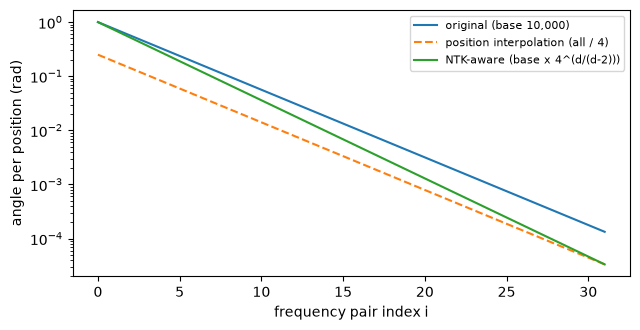

In [18]:
D, BASE, TRAINED = 64, 10000.0, 4096
theta = rope_frequencies(D, BASE)
last = D // 2 - 1

for s in (2.0, 4.0, 8.0, 40.0):
    scaled = rope_frequencies(D, ntk_aware_base(BASE, s, D))
    assert abs(scaled[0] - theta[0]) < 1e-12                       # highest frequency unchanged
    assert abs(theta[last] / scaled[last] - s) < 1e-9 * s          # lowest divided by exactly s

# Position interpolation, s = 4: trained on positions 0 .. L-1, extended to 0 .. L*s-1.
s = 4.0
low = [i for i in range(D // 2) if TRAINED * theta[i] < 2 * math.pi]   # turn less than once in training
high = [i for i in range(D // 2) if TRAINED * theta[i] >= 2 * math.pi]
seen = TRAINED * theta[low]                                            # largest angle seen in training
interpolated = (TRAINED - 1 / s) * theta[low]                          # largest angle after dividing positions by s
extrapolated = (TRAINED * s - 1) * theta[low]                          # largest angle when positions are not rescaled
assert len(low) > 0 and last in low
assert torch.all(interpolated < seen) and torch.all(extrapolated > seen)
assert high[0] == 0 and all(TRAINED * theta[i] > 2 * math.pi for i in high)  # these wrap many times already
print(f"{len(low)} of {D // 2} frequency pairs turn less than once in {TRAINED} positions; "
      f"interpolation keeps them inside the trained range, extrapolation does not")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
index = np.arange(D // 2)
ax.semilogy(index, theta.numpy(), label="original (base 10,000)")
ax.semilogy(index, (theta / s).numpy(), "--", label="position interpolation (all / 4)")
ax.semilogy(index, rope_frequencies(D, ntk_aware_base(BASE, s, D)).numpy(), label="NTK-aware (base x 4^(d/(d-2)))")
ax.set_xlabel("frequency pair index i")
ax.set_ylabel("angle per position (rad)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

(nb-arch-moe)=
## 6. A Mixture-of-Experts Router

The router from the chapter, run on 4,096 random tokens with 8 experts and top-2 routing. Each row of the router weight has unit norm, so no expert is favoured at initialisation, and the dispatch fraction of an expert is its share of the routed slots (they sum to one).

In [19]:
import torch


def route_top_k(x, router_weight, k):
    """x: [tokens, d]; router_weight: [experts, d].

    Returns the chosen expert ids [tokens, k], their gate weights [tokens, k], and the
    load-balancing loss of Fedus et al., n_experts * sum_i f_i * P_i.
    """
    n_experts = router_weight.size(0)
    probs = (x @ router_weight.T).softmax(dim=-1)
    top_p, top_i = probs.topk(k, dim=-1)
    gates = top_p / top_p.sum(dim=-1, keepdim=True)
    counts = torch.bincount(top_i.flatten(), minlength=n_experts).float()
    f = counts / counts.sum()  # fraction of routed slots sent to each expert; sums to 1
    p = probs.mean(dim=0)  # mean router probability of each expert
    return top_i, gates, n_experts * (f * p).sum()

largest deviation of any expert's share from 1/8 over 20 seeds: 0.0166 (tolerance 0.03)
load-balancing loss: balanced 1.000, biased 2.799 (uniform routing gives 1)
balanced  router drops    87 of 8192 slots at capacity factor 1.0
biased    router drops  2998 of 8192 slots at capacity factor 1.0


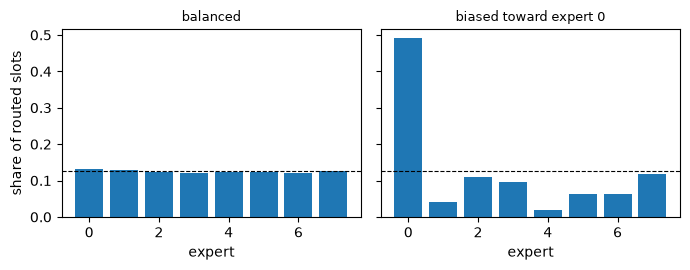

In [20]:
E, K, T, D_MODEL = 8, 2, 4096, 64


def make_router(seed):
    g = torch.Generator().manual_seed(seed)
    w = torch.randn(E, D_MODEL, generator=g)
    return w / w.norm(dim=-1, keepdim=True), torch.randn(T, D_MODEL, generator=g)


# Spread of the dispatch fractions over 20 seeds, which sets the tolerance used below
deviations = []
for seed in range(20):
    w, x = make_router(seed)
    ids, _, _ = route_top_k(x, w, K)
    f = torch.bincount(ids.flatten(), minlength=E).float() / (T * K)
    deviations.append((f - 1 / E).abs().max().item())
TOL = 0.03
print(f"largest deviation of any expert's share from 1/{E} over 20 seeds: {max(deviations):.4f} (tolerance {TOL})")
assert max(deviations) < TOL

w, x = make_router(0)
ids, gates, aux_balanced = route_top_k(x, w, K)
assert torch.allclose(gates.sum(-1), torch.ones(T)) and ids.shape == (T, K)

# A router that favours expert 0: shift every token towards its weight row
ids_b, _, aux_biased = route_top_k(x + 3 * w[0], w, K)
print(f"load-balancing loss: balanced {aux_balanced:.3f}, biased {aux_biased:.3f} (uniform routing gives 1)")
assert 0.95 < aux_balanced < 1.1 and aux_biased > 2

# Capacity factor 1.0: each expert takes at most ceil(c * k * T / E) slots, in token order
CAPACITY = math.ceil(1.0 * K * T / E)


def dropped_vectorised(ids):
    flat = ids.flatten()                                            # slot order: token-major
    onehot = F.one_hot(flat, E)
    position = (onehot.cumsum(0) - 1).gather(1, flat[:, None])[:, 0]   # rank within its expert
    return int((position >= CAPACITY).sum())


def dropped_loop(ids):
    taken, dropped = [0] * E, 0
    for expert in ids.flatten().tolist():
        if taken[expert] >= CAPACITY:
            dropped += 1
        else:
            taken[expert] += 1
    return dropped


for name, routed in (("balanced", ids), ("biased", ids_b)):
    assert dropped_vectorised(routed) == dropped_loop(routed)
    print(f"{name:9} router drops {dropped_loop(routed):5d} of {T * K} slots at capacity factor 1.0")
assert dropped_loop(ids_b) > 5 * max(dropped_loop(ids), 1)

fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharey=True)
for ax, (name, routed) in zip(axes, (("balanced", ids), ("biased toward expert 0", ids_b))):
    ax.bar(range(E), torch.bincount(routed.flatten(), minlength=E).numpy() / (T * K))
    ax.axhline(1 / E, color="k", lw=0.8, ls="--")
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("expert")
axes[0].set_ylabel("share of routed slots")
plt.tight_layout()
plt.show()

A full layer, checked against a per-token reference that follows Mixtral's formulation literally: take the top-2 router *logits*, then apply a softmax over just those two. The chapter's router renormalises the full softmax over the selected pair, which is the same thing. The layer is then placed in a small model, and its total and active parameters are compared with `count_params`.

In [21]:
class MoELayer(nn.Module):
    def __init__(self, d_model, n_experts, top_k, hidden):
        super().__init__()
        self.top_k = top_k
        self.router = nn.Linear(d_model, n_experts, bias=False)
        self.experts = nn.ModuleList([SwiGLU(d_model, hidden) for _ in range(n_experts)])

    def forward(self, x):
        flat = x.reshape(-1, x.shape[-1])
        top_p, top_i = self.router(flat).softmax(-1).topk(self.top_k, dim=-1)
        gates = top_p / top_p.sum(-1, keepdim=True)
        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            token, slot = (top_i == e).nonzero(as_tuple=True)
            if token.numel():
                out.index_add_(0, token, gates[token, slot].unsqueeze(-1) * expert(flat[token]))
        return out.view(x.shape)


def moe_reference(layer, x):
    flat, rows = x.reshape(-1, x.shape[-1]), []
    for t in range(flat.shape[0]):
        logits, chosen = layer.router(flat[t]).topk(layer.top_k)
        g = logits.softmax(-1)                                       # softmax over the selected logits
        rows.append(sum(g[j] * layer.experts[int(chosen[j])](flat[t]) for j in range(layer.top_k)))
    return torch.stack(rows).view(x.shape)


layer = MoELayer(64, 8, 2, 96).double()
x = torch.randn(2, 6, 64, dtype=torch.float64)
with torch.no_grad():
    assert torch.allclose(layer(x), moe_reference(layer, x), atol=1e-10)

# One expert with one slot is just the dense feed-forward network
one = MoELayer(64, 1, 1, 96).double()
with torch.no_grad():
    assert torch.allclose(one(x), one.experts[0](x), atol=1e-12)

# Total and active parameters of a small sparse model
moe_model = TinyLM(n_kv_heads=2)
for block in moe_model.blocks:
    block.ffn = MoELayer(64, 8, 2, 96)
cfg = {"model_type": "mixtral", "hidden_size": 64, "num_hidden_layers": 4, "num_attention_heads": 4,
       "num_key_value_heads": 2, "intermediate_size": 96, "num_local_experts": 8,
       "num_experts_per_tok": 2, "vocab_size": 256, "tie_word_embeddings": True}
counts = count_params(cfg)
total = sum(p.numel() for p in moe_model.parameters())
idle = 4 * (8 - 2) * sum(p.numel() for p in moe_model.blocks[0].ffn.experts[0].parameters())
assert total == counts["total"] and total - idle == counts["active_with_embedding"]
print(f"sparse toy model: {total:,} total parameters, {total - idle:,} active per token "
      f"({100 * (total - idle) / total:.0f}%)")

sparse toy model: 657,984 total parameters, 215,616 active per token (33%)


(nb-arch-train)=
## 7. Post-Norm Against Pre-Norm

A six-layer byte-level model (about 0.3 million parameters) is trained on the first 150 KB of *Pride and Prejudice*, once with each norm placement, at a learning rate of $3 \times 10^{-3}$ with no warm-up, for 400 steps of 8 sequences of 64 bytes. A model that has only learned byte frequencies sits near a loss of 3.1 nats; anything lower means it is using context. For each of five seeds both variants see the same batches. The score is the mean training loss over the last 20 steps. Everything is single-threaded and deterministic, so a seed reproduces exactly.

In [22]:
raw = (DATA / "pride_and_prejudice_150k.txt").read_bytes()
assert sha256(raw) == CHECKSUMS["pride_and_prejudice_150k.txt"]
TEXT = torch.tensor(list(raw), dtype=torch.long)
BATCH, SEQ, STEPS, LR = 8, 64, 400, 3e-3


def train(style, seed):
    torch.manual_seed(seed)
    model = TinyLM(n_layers=6, n_kv_heads=4, style=style)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(1000 + seed)           # the same batches for both variants
    losses = []
    for _ in range(STEPS):
        start = torch.randint(0, len(TEXT) - SEQ - 1, (BATCH,), generator=g)
        index = start[:, None] + torch.arange(SEQ + 1)
        batch = TEXT[index]
        loss = F.cross_entropy(model(batch[:, :-1]).reshape(-1, 256), batch[:, 1:].reshape(-1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses


print(f"{sum(p.numel() for p in TinyLM(n_layers=6, n_kv_heads=4).parameters()):,} parameters; "
      f"{BATCH * SEQ:,} tokens per step; unigram-uniform loss is ln 256 = {math.log(256):.3f}")
RESULTS = {"pre": [], "post": []}

311,360 parameters; 512 tokens per step; unigram-uniform loss is ln 256 = 5.545


One cell per run keeps each well inside the time limit of a notebook cell on a small machine (a run takes about twenty seconds on one thread).

In [23]:
with timed("pre-norm, seed 0"):
    RESULTS["pre"].append(train("pre", 0))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["pre"][-1][-20:])), 3))

[pre-norm, seed 0: 22.3 s]
final loss (mean of last 20 steps): 2.12


In [24]:
with timed("pre-norm, seed 1"):
    RESULTS["pre"].append(train("pre", 1))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["pre"][-1][-20:])), 3))

[pre-norm, seed 1: 22.2 s]
final loss (mean of last 20 steps): 2.061


In [25]:
with timed("pre-norm, seed 2"):
    RESULTS["pre"].append(train("pre", 2))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["pre"][-1][-20:])), 3))

[pre-norm, seed 2: 22.0 s]
final loss (mean of last 20 steps): 2.144


In [26]:
with timed("pre-norm, seed 3"):
    RESULTS["pre"].append(train("pre", 3))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["pre"][-1][-20:])), 3))

[pre-norm, seed 3: 23.0 s]
final loss (mean of last 20 steps): 2.11


In [27]:
with timed("pre-norm, seed 4"):
    RESULTS["pre"].append(train("pre", 4))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["pre"][-1][-20:])), 3))

[pre-norm, seed 4: 22.6 s]
final loss (mean of last 20 steps): 2.128


In [28]:
with timed("post-norm, seed 0"):
    RESULTS["post"].append(train("post", 0))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["post"][-1][-20:])), 3))

[post-norm, seed 0: 22.3 s]
final loss (mean of last 20 steps): 3.111


In [29]:
with timed("post-norm, seed 1"):
    RESULTS["post"].append(train("post", 1))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["post"][-1][-20:])), 3))

[post-norm, seed 1: 22.2 s]
final loss (mean of last 20 steps): 3.113


In [30]:
with timed("post-norm, seed 2"):
    RESULTS["post"].append(train("post", 2))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["post"][-1][-20:])), 3))

[post-norm, seed 2: 23.3 s]
final loss (mean of last 20 steps): 3.135


In [31]:
with timed("post-norm, seed 3"):
    RESULTS["post"].append(train("post", 3))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["post"][-1][-20:])), 3))

[post-norm, seed 3: 22.6 s]
final loss (mean of last 20 steps): 3.118


In [32]:
with timed("post-norm, seed 4"):
    RESULTS["post"].append(train("post", 4))
print("final loss (mean of last 20 steps):", round(float(np.mean(RESULTS["post"][-1][-20:])), 3))

[post-norm, seed 4: 22.3 s]
final loss (mean of last 20 steps): 3.115


pre  2.113 +- 0.028
post 3.118 +- 0.009
gap per seed [0.99  1.052 0.991 1.008 0.987]; mean gap 1.006 = 35.9x the larger spread
pre-norm beats post-norm in every seed by more than 3x the seed spread: True


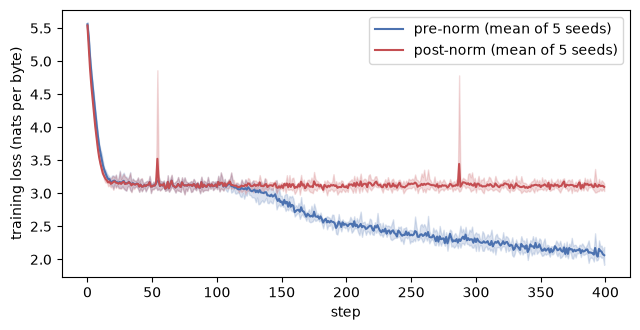

In [33]:
final = {style: np.array([np.mean(r[-20:]) for r in runs]) for style, runs in RESULTS.items()}
gap = final["post"] - final["pre"]
spread = max(final["pre"].std(), final["post"].std())
print(f"pre  {final['pre'].mean():.3f} +- {final['pre'].std():.3f}")
print(f"post {final['post'].mean():.3f} +- {final['post'].std():.3f}")
print(f"gap per seed {np.round(gap, 3)}; mean gap {gap.mean():.3f} = {gap.mean() / spread:.1f}x the larger spread")

assert all(np.isfinite(v).all() for v in final.values())
POSITIVE_RESULT = bool((gap > 0).all() and gap.mean() > 3 * spread)
print("pre-norm beats post-norm in every seed by more than 3x the seed spread:", POSITIVE_RESULT)

# Reproducibility: re-running one seed gives the identical curve
assert train("pre", 0) == RESULTS["pre"][0]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for style, color in (("pre", "#4c72b0"), ("post", "#c44e52")):
    curves = np.array(RESULTS[style])
    ax.plot(curves.mean(0), color=color, label=f"{style}-norm (mean of {len(curves)} seeds)")
    ax.fill_between(range(STEPS), curves.min(0), curves.max(0), color=color, alpha=0.2)
ax.set_xlabel("step")
ax.set_ylabel("training loss (nats per byte)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Summary

- The parameter counter reproduces the stored tensors of seven checkpoints and the published totals of three more, exactly, and the vendors' own "active" figures only under the convention each vendor uses.
- Grouped-query attention is multi-head attention with shared key/value weights; the cache is smaller by exactly the ratio of head counts, and decoding with it equals the full pass.
- A latent cache stores `d_c + d_rope` numbers per token and gives the same attention output as the expanded keys and values.
- NTK-aware scaling keeps the highest rotation frequency and divides the lowest by the scale; interpolation keeps the low frequencies inside the angles seen in training.
- A top-k router with an auxiliary loss distributes tokens evenly when it is balanced; capacity limits drop the overflow of a router that is not.